In [1]:
# Xây dựng mô hình LeNet
import torch
import torch.nn as nn

class LeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        # Xây dựng phần trích xuất đặc trưng
        self.features = nn.Sequential(
            # Conv 1: 3 x 28 x 28 -> 6 x 28 x 28
            nn.Conv2d(3, 6, kernel_size=5, padding=2),
            nn.Tanh(),

            # Pool 1: 6 x 28 x 28 -> 6 x 14 x 14
            nn.AvgPool2d(kernel_size=2, stride=2),

            # Conv 2: 6 x 14 x 14 -> 16 x 10 x 10
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),

            # Pool 2: 16 x 10 x 10 -> 16 x 5 x 5
            nn.AvgPool2d(kernel_size=2, stride=2)
        )

        # Xây dựng phần phân loại
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = LeNet(num_classes=21).to(device)
print(model)

LeNet(
  (features): Sequential(
    (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=21, bias=True)
  )
)


In [2]:
# Chuẩn bị dữ liệu VinaFood21
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [3]:
transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [7]:
DATA_DIR = r"C:\Users\Thao\Downloads\VinaFood21\VinaFood21"

import os
from torchvision import datasets
from torch.utils.data import DataLoader, random_split
import torch

# Load dữ liệu train và val
full_train_ds = datasets.ImageFolder(
    root=os.path.join(DATA_DIR, "train"),
    transform=transform
)

test_ds = datasets.ImageFolder(
    root=os.path.join(DATA_DIR, "val"),
    transform=transform
)

assert len(full_train_ds.classes) == 21
assert full_train_ds.class_to_idx == test_ds.class_to_idx

# Chia train thành 90% train và 10% validation
n_train = int(0.9 * len(full_train_ds))
n_val = len(full_train_ds) - n_train

train_ds, val_ds = random_split(
    full_train_ds,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42)
)

# Tạo DataLoader
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False)
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False)

# Dùng cho classification_report và confusion matrix
dataset = full_train_ds

print("\nTrain:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))

Số lớp: 21
Tên các lớp: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']
Số ảnh train ban đầu: 10044
Số ảnh val gốc: 6682

Train: 9039
Validation: 1005
Test: 6682


In [8]:
# Huấn luyện LeNet bằng Adam
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 20

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
# một decorator yêu cầu PyTorch không xây dựng đồ thị tính gradient trong hàm validate().
def validate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total

In [10]:
train_losses = [] # Loss của tập train qua mỗi epoch
val_losses = [] # Loss của tập validation qua mỗi epoch
train_accs = [] # Accuracy của tập train qua mỗi epoch
val_accs = [] # Accuracy của tập validation qua mỗi epoch

best_val_loss = float("inf")
# float("inf") biểu diễn dương vô cực trong Python.

for epoch in range(EPOCHS):

    train_loss, train_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )

    val_loss, val_acc = validate(
        model, val_dl, criterion, device
    )
    # Mô hình không học từ dữ liệu Validation nên không cần truyền optimizer vào hàm.

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_lenet.pth")
        # model.state_dict() trả về một dict chứa các tham số của mô hình: weight, bias...

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

C:\Users\Thao\AppData\Local\Programs\Python\Python313\Lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/20] | Train Loss: 2.7531 | Train Acc: 0.1656 | Val Loss: 2.6284 | Val Acc: 0.2060
Epoch [2/20] | Train Loss: 2.5686 | Train Acc: 0.2182 | Val Loss: 2.5698 | Val Acc: 0.2030
Epoch [3/20] | Train Loss: 2.4821 | Train Acc: 0.2400 | Val Loss: 2.5204 | Val Acc: 0.2259
Epoch [4/20] | Train Loss: 2.4166 | Train Acc: 0.2577 | Val Loss: 2.4925 | Val Acc: 0.2279
Epoch [5/20] | Train Loss: 2.3513 | Train Acc: 0.2766 | Val Loss: 2.4600 | Val Acc: 0.2488
Epoch [6/20] | Train Loss: 2.2801 | Train Acc: 0.2951 | Val Loss: 2.4443 | Val Acc: 0.2478
Epoch [7/20] | Train Loss: 2.2145 | Train Acc: 0.3198 | Val Loss: 2.4518 | Val Acc: 0.2537
Epoch [8/20] | Train Loss: 2.1430 | Train Acc: 0.3441 | Val Loss: 2.4417 | Val Acc: 0.2597
Epoch [9/20] | Train Loss: 2.0674 | Train Acc: 0.3641 | Val Loss: 2.4556 | Val Acc: 0.2587
Epoch [10/20] | Train Loss: 1.9857 | Train Acc: 0.3877 | Val Loss: 2.4935 | Val Acc: 0.2567
Epoch [11/20] | Train Loss: 1.9047 | Train Acc: 0.4113 | Val Loss: 2.5176 | Val Acc: 0.26

In [11]:
# Đánh giá Accuracy, Precision, Recall và F1-macro
model.load_state_dict(
    torch.load(
        "best_lenet.pth",
        map_location=device,
        weights_only=True
        # Tham số này yêu cầu PyTorch sử dụng cơ chế tải giới hạn
        # chủ yếu dành cho tensor, kiểu dữ liệu cơ bản và các cấu trúc như state_dict.
    )
)
# Nếu không load lại state_dict, nó sẽ dùng trọng số của epoch cuối cùng

model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_dl:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-macro:", f1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(21)),
    target_names=dataset.classes,
    zero_division=0
))

Accuracy: 0.24019754564501647
Precision: 0.2144926722814015
Recall: 0.22233353695551067
F1-macro: 0.20798516804817832
                  precision    recall  f1-score   support

        banh-can       0.22      0.08      0.12       241
        banh-hoi       0.27      0.39      0.32       607
    banh-mi-chao       0.26      0.22      0.24       289
        banh-tet       0.09      0.13      0.11       364
 banh-trang-tron       0.14      0.07      0.10       309
          banh-u       0.06      0.01      0.01       176
        banh-uot       0.24      0.24      0.24       560
       bap-nuong       0.02      0.01      0.01       143
          bo-kho       0.22      0.31      0.26       338
       bo-la-lot       0.35      0.52      0.42       458
       bot-chien       0.17      0.16      0.16       276
           ca-ri       0.13      0.10      0.11       171
    canh-kho-qua       0.29      0.55      0.38       290
   canh-khoai-mo       0.68      0.57      0.62       198
        ga-

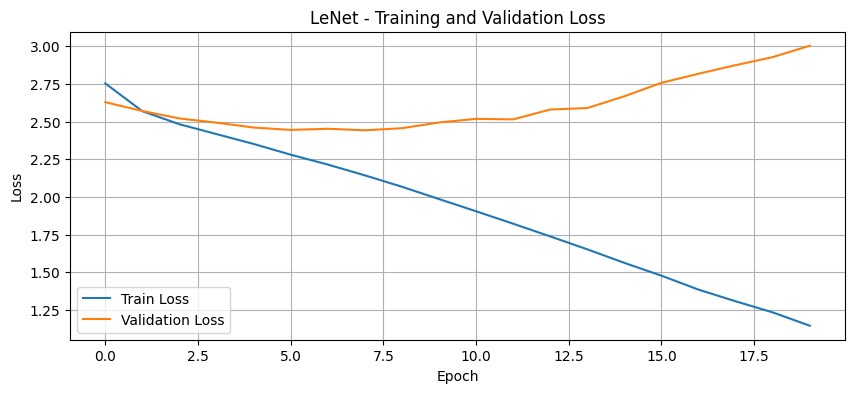

In [12]:
plt.figure(figsize=(10, 4))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

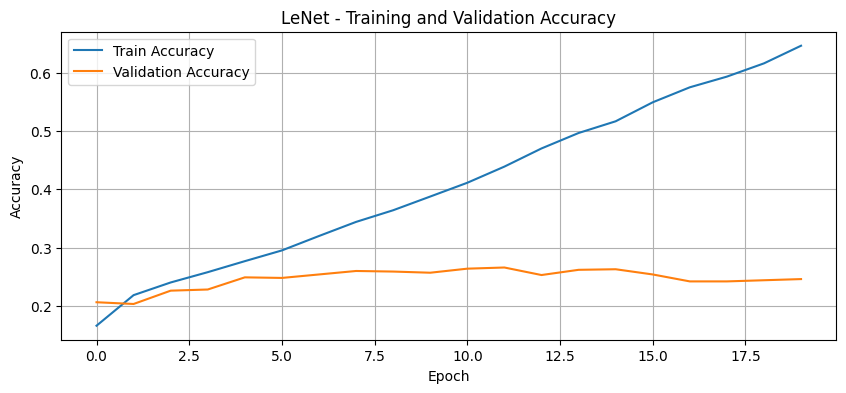

In [13]:
plt.figure(figsize=(10, 4))

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LeNet - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

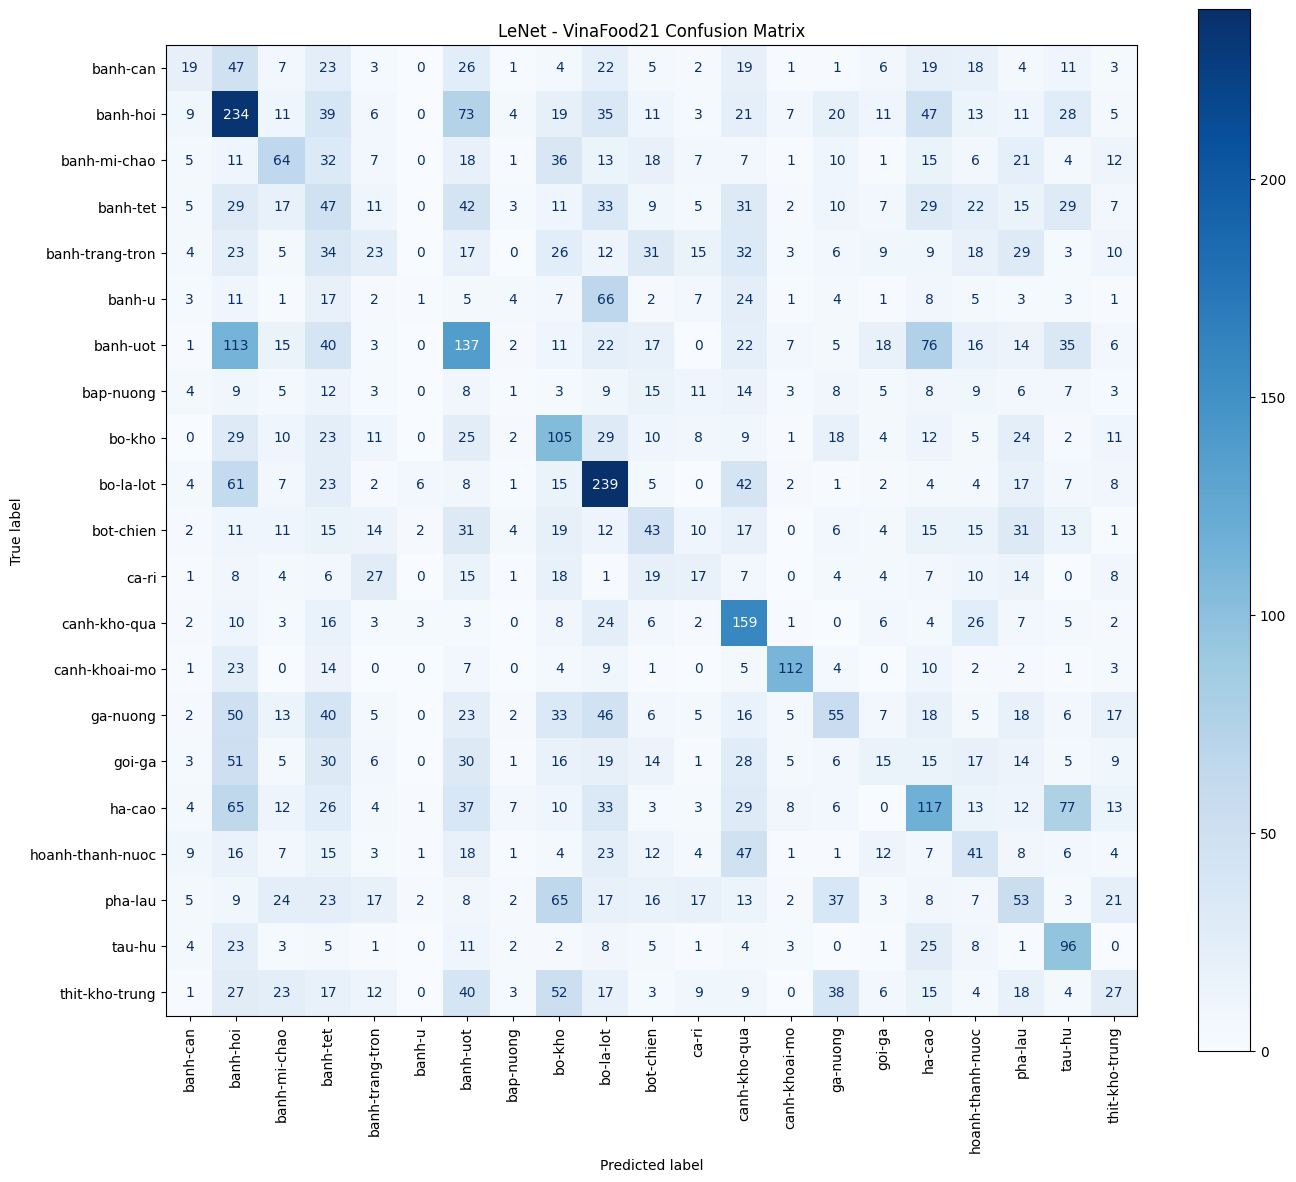

In [17]:
classes = full_train_ds.classes 

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(21)),
    display_labels=classes,
    cmap="Blues",
    xticks_rotation=90,
    ax=ax
)

plt.title("LeNet - VinaFood21 Confusion Matrix")
plt.tight_layout()
plt.show()